# Water Raman & tonic-water measurement report

Metrology-style analysis of DIY-fixture baselines on the bench LS 55 (not factory `L2250140` validation).

| Series | Experiment | Optics |
| --- | --- | --- |
| `20261103-1629` | Distilled-water Raman | Ex 350 nm, Em 380–420 nm, slits 10 nm |
| `20261103-194005` | Tonic quinine emission (~1:450) + clipped scouts | Ex 350 nm, Em 400–550 nm, slits 5 nm |

**Intensity unit:** blank-subtracted PMT ADC counts. Excitation correction (`$CX`) may be ON; **no emission spectral correction** is applied. Do **not** treat DIY absolute-peak SNR or Δλ as brochure `500:1` / `±1.0 nm` claims.

Primary evidence: continuum residual ΔI, contrast SNR, peak λ uncertainty (technical vs reseat). Spatial-frequency FFT/Welch is a QC appendix only.


In [1]:
from __future__ import annotations

import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import curve_fit
from scipy.signal import savgol_filter, welch

# Prefer the editable install from `uv sync`; fall back to repo-root on sys.path.
import ls55 as _ls55

REPO = Path(_ls55.__file__).resolve().parents[1]
if not (REPO / "logs").is_dir():
    # Running from a weird cwd / non-editable install: locate repo from cwd.
    REPO = Path.cwd().resolve()
    if not (REPO / "ls55").is_dir():
        REPO = REPO.parent
    if str(REPO) not in sys.path:
        sys.path.insert(0, str(REPO))

from ls55.review import (
    CLIP_THRESHOLD,
    blank_settings_compatible,
    compute_contrast_snr,
    compute_wing_continuum_residual,
)

plt.rcParams.update(
    {
        "figure.figsize": (9, 4.5),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
    }
)

WATER_DIR = REPO / "logs" / "water-raman"
TONIC_DIR = REPO / "logs" / "tonic-water"
WATER_SERIES = "20261103-1629"
TONIC_GATE_SERIES = "20261103-194005"
WATER_GUIDE_NM = 397.0
TONIC_GUIDE_NM = 450.0
WATER_RAMAN_GUIDE_CM1 = 3400.0  # O–H stretch ~3400 cm⁻¹
WEAK_WATER_RESEATS = {"164227", "164351"}
BRINGUP_SN = "79787"
BRINGUP_FW = "F1"

print("REPO:", REPO)
print("numpy", np.__version__, "scipy", scipy.__version__, "pandas", pd.__version__)


REPO: /home/plastic/src/spectrometer-lab
numpy 2.4.6 scipy 1.17.1 pandas 3.1.1


## 0. Measurement report header (provenance)

Instrument identity, locked optics, blank paths, software versions, and DIY-fixture scope.


In [2]:
def git_short() -> str:
    try:
        return (
            subprocess.check_output(
                ["git", "rev-parse", "--short", "HEAD"],
                cwd=REPO,
                stderr=subprocess.DEVNULL,
                text=True,
            ).strip()
        )
    except Exception:
        return "(unavailable)"


def load_run(json_path: Path) -> dict | None:
    meta = json.loads(json_path.read_text())
    experiment = meta.get("experiment")
    if experiment not in {"water-raman", "tonic-water"}:
        return None
    csv_path = json_path.with_suffix(".csv")
    if not csv_path.is_file():
        return None
    df = pd.read_csv(csv_path)
    stamp = json_path.stem.split("-", 2)[-1]
    peaks = meta.get("peaks") or []
    peak0 = peaks[0] if peaks else {}
    peak_block = meta.get("peak") or {}
    snr_block = meta.get("snr") or {}
    expected = meta.get("expected") or {}
    settings = meta.get("settings") or {}
    guide = float(
        peak_block.get("guide_nm")
        or peak0.get("guide_nm")
        or expected.get("guide_nm")
        or (WATER_GUIDE_NM if experiment == "water-raman" else TONIC_GUIDE_NM)
    )
    observed_nm = peak_block.get("observed_nm", peak0.get("observed_nm"))
    observed_i = peak_block.get("observed_intensity", peak0.get("observed_intensity"))
    delta_nm = peak_block.get("delta_nm")
    if delta_nm is None and observed_nm is not None:
        delta_nm = float(observed_nm) - guide
    return {
        "run_id": json_path.stem,
        "stamp": stamp,
        "experiment": experiment,
        "series_id": meta.get("series_id"),
        "replicate_kind": meta.get("replicate_kind") or "other",
        "sample": meta.get("sample"),
        "dilution": meta.get("dilution"),
        "clipped": bool(meta.get("clipped", False)),
        "max_abs_intensity": meta.get("max_abs_intensity"),
        "guide_nm": guide,
        "peak_nm": observed_nm,
        "peak_intensity": observed_i,
        "delta_nm": delta_nm,
        "abs_snr": snr_block.get("snr"),
        "ex_nm": settings.get("ex_nm", expected.get("ex_nm", 350.0)),
        "slit_nm": settings.get("slit_nm"),
        "speed": settings.get("speed"),
        "interval_nm": settings.get("interval_nm"),
        "em_lo": settings.get("em_lo"),
        "em_hi": settings.get("em_hi"),
        "blank_csv": meta.get("blank_csv"),
        "settings": settings,
        "json_path": json_path,
        "csv_path": csv_path,
        "spectrum": df,
        "meta": meta,
    }


def load_catalog(log_dir: Path, prefix: str) -> list[dict]:
    runs = []
    for path in sorted(log_dir.glob(f"{prefix}-*.json")):
        if "summary" in path.stem:
            continue
        run = load_run(path)
        if run is not None:
            runs.append(run)
    return runs


water_runs = [r for r in load_catalog(WATER_DIR, "water-raman") if r["series_id"] == WATER_SERIES]
tonic_all = load_catalog(TONIC_DIR, "tonic-water")
tonic_gate = [r for r in tonic_all if r["series_id"] == TONIC_GATE_SERIES]
tonic_scouts = [r for r in tonic_all if r["series_id"] != TONIC_GATE_SERIES]

# Firmware revision from first water status if present
fw = BRINGUP_FW
st0 = (water_runs[0]["meta"].get("dark") or {}).get("status") or {}
if st0.get("revision"):
    fw = st0["revision"]

blank_paths = sorted(
    {
        str(REPO / r["blank_csv"]) if r.get("blank_csv") and not Path(r["blank_csv"]).is_absolute()
        else str(r.get("blank_csv"))
        for r in water_runs + tonic_gate
        if r.get("blank_csv")
    }
)

w0, t0 = water_runs[0], tonic_gate[0]
header = pd.DataFrame(
    [
        ("Instrument", f"PerkinElmer LS 55, FW {fw}, SN {BRINGUP_SN} (bring-up identity)"),
        ("Fixture", "DIY Al square-bore block — Gate D open; NOT factory L2250140"),
        ("Water series", WATER_SERIES),
        ("Tonic gate series", TONIC_GATE_SERIES),
        (
            "Water optics",
            f"Ex {w0['ex_nm']} nm, Em {w0['em_lo']}–{w0['em_hi']} nm, "
            f"slit {w0['slit_nm']} nm, {w0['speed']} nm/min, step {w0['interval_nm']} nm",
        ),
        (
            "Tonic optics",
            f"Ex {t0['ex_nm']} nm, Em {t0['em_lo']}–{t0['em_hi']} nm, "
            f"slit {t0['slit_nm']} nm, {t0['speed']} nm/min, step {t0['interval_nm']} nm",
        ),
        ("Water sample", w0.get("sample")),
        ("Tonic sample / dilution", f"{t0.get('sample')} ({t0.get('dilution')})"),
        ("Blank CSVs", "; ".join(blank_paths)),
        ("Intensity unit", "blank-subtracted PMT counts (no Em spectral correction)"),
        ("Brochure claims", "DIY usefulness only — not 500:1 / ±1.0 nm / ±0.5 nm factory validation"),
        ("Software", f"numpy {np.__version__}, scipy {scipy.__version__}, pandas {pd.__version__}"),
        ("Git", git_short()),
        ("n water / tonic gate / scouts", f"{len(water_runs)} / {len(tonic_gate)} / {len(tonic_scouts)}"),
    ],
    columns=["Field", "Value"],
)
display(header)


,Field,Value
0,Instrument,"PerkinElmer LS 55, FW F1, SN 79787 (bring-up i..."
1,Fixture,DIY Al square-bore block — Gate D open; NOT fa...
2,Water series,20261103-1629
3,Tonic gate series,20261103-194005
4,Water optics,"Ex 350.0 nm, Em 380.0–420.0 nm, slit 10.0 nm, ..."
5,Tonic optics,"Ex 350.0 nm, Em 400.0–550.0 nm, slit 5.0 nm, 1..."
6,Water sample,distilled water
7,Tonic sample / dilution,tonic water ~1:450 (~1:450)
8,Blank CSVs,/home/plastic/src/spectrometer-lab/logs/freepa...
9,Intensity unit,blank-subtracted PMT counts (no Em spectral co...


## 1. Load catalog

Join each experiment `*.json` sidecar with its corrected CSV (`wavelength_nm,sample_on,blank,corrected`).


In [3]:
catalog = water_runs + tonic_all
meta_df = pd.DataFrame(
    [
        {
            k: r[k]
            for k in (
                "run_id",
                "stamp",
                "experiment",
                "series_id",
                "replicate_kind",
                "dilution",
                "clipped",
                "guide_nm",
                "peak_nm",
                "peak_intensity",
                "delta_nm",
                "abs_snr",
                "max_abs_intensity",
                "slit_nm",
                "ex_nm",
            )
        }
        for r in catalog
    ]
)
display(meta_df)


,run_id,stamp,experiment,series_id,replicate_kind,dilution,clipped,guide_nm,peak_nm,peak_intensity,delta_nm,abs_snr,max_abs_intensity,slit_nm,ex_nm
0,water-raman-20261103-162931,20261103-162931,water-raman,20261103-1629,sanity,NaN,False,397.0,394.0,18844.0,-3.0,104.323138,NaN,10.0,350.0
1,water-raman-20261103-163033,20261103-163033,water-raman,20261103-1629,technical,NaN,False,397.0,396.0,18953.0,-1.0,118.335613,NaN,10.0,350.0
2,water-raman-20261103-163140,20261103-163140,water-raman,20261103-1629,technical,NaN,False,397.0,394.0,18906.0,-3.0,84.331319,NaN,10.0,350.0
3,water-raman-20261103-163233,20261103-163233,water-raman,20261103-1629,technical,NaN,False,397.0,394.0,18907.0,-3.0,90.880602,NaN,10.0,350.0
4,water-raman-20261103-163327,20261103-163327,water-raman,20261103-1629,technical,NaN,False,397.0,396.0,18776.0,-1.0,148.595797,NaN,10.0,350.0
5,water-raman-20261103-163421,20261103-163421,water-raman,20261103-1629,technical,NaN,False,397.0,396.0,18821.0,-1.0,143.270541,NaN,10.0,350.0
6,water-raman-20261103-163731,20261103-163731,water-raman,20261103-1629,reseat,NaN,False,397.0,398.0,8571.0,1.0,104.286846,NaN,10.0,350.0
7,water-raman-20261103-163912,20261103-163912,water-raman,20261103-1629,reseat,NaN,False,397.0,396.0,12505.0,-1.0,107.193152,NaN,10.0,350.0
8,water-raman-20261103-164058,20261103-164058,water-raman,20261103-1629,reseat,NaN,False,397.0,396.0,9099.0,-1.0,139.248208,NaN,10.0,350.0
9,water-raman-20261103-164227,20261103-164227,water-raman,20261103-1629,reseat,NaN,False,397.0,390.0,32037.0,-7.0,141.425370,NaN,10.0,350.0


## 2. EDA overlays

Blank-corrected emission colored by `replicate_kind`. Titles carry series IDs; axes in nm / counts.


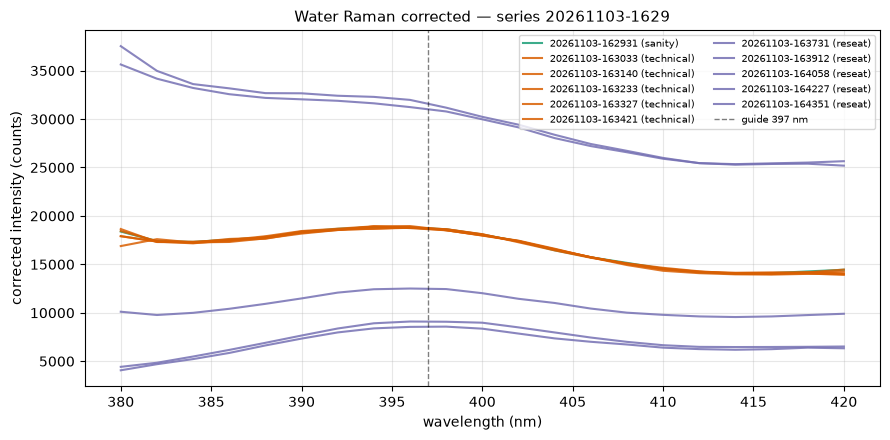

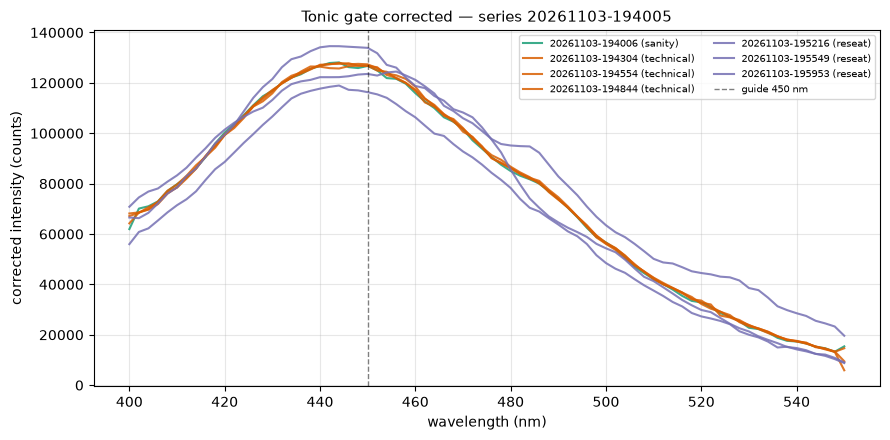

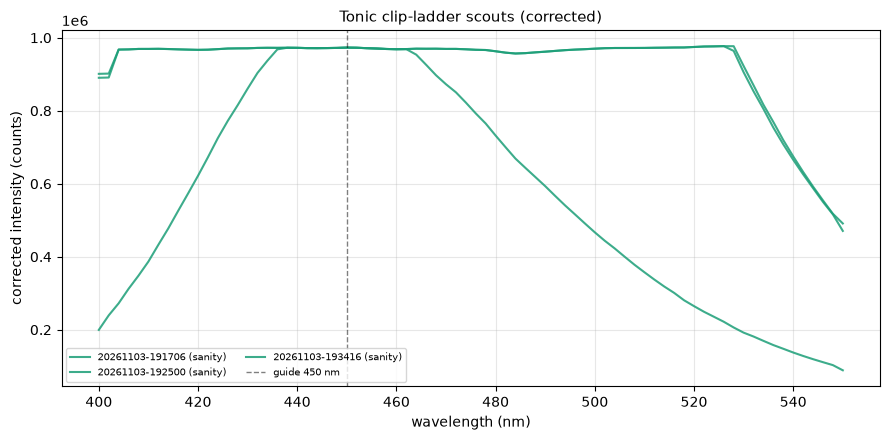

In [4]:
KIND_COLORS = {
    "sanity": "#1b9e77",
    "technical": "#d95f02",
    "reseat": "#7570b3",
    "other": "#666666",
}


def plot_overlays(runs: list[dict], title: str, guide_nm: float | None = None):
    fig, ax = plt.subplots()
    for r in runs:
        sp = r["spectrum"]
        kind = r["replicate_kind"]
        ax.plot(
            sp["wavelength_nm"],
            sp["corrected"],
            color=KIND_COLORS.get(kind, "#333"),
            alpha=0.85,
            label=f"{r['stamp']} ({kind})",
        )
    if guide_nm is not None:
        ax.axvline(guide_nm, color="k", ls="--", lw=1, alpha=0.5, label=f"guide {guide_nm:g} nm")
    ax.set_xlabel("wavelength (nm)")
    ax.set_ylabel("corrected intensity (counts)")
    ax.set_title(title)
    ax.legend(fontsize=7, ncol=2, loc="best")
    fig.tight_layout()
    return fig


plot_overlays(
    water_runs,
    f"Water Raman corrected — series {WATER_SERIES}",
    WATER_GUIDE_NM,
)
plot_overlays(
    tonic_gate,
    f"Tonic gate corrected — series {TONIC_GATE_SERIES}",
    TONIC_GUIDE_NM,
)
if tonic_scouts:
    plot_overlays(tonic_scouts, "Tonic clip-ladder scouts (corrected)", TONIC_GUIDE_NM)
plt.show()


## 3. Blank & dynamic-range QC

Matched blank under the sample curve; freepath settings compatibility; tonic clip fraction vs dilution (working range for unclipped fluorescence — not a Beer’s-law claim).


,group,ok,notes
0,water,True,settings match
1,tonic_gate,True,settings match


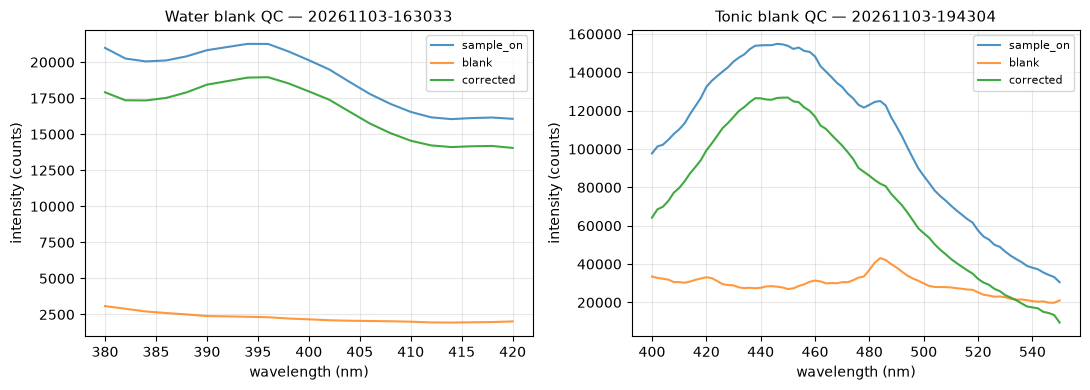

,stamp,series_id,dilution,kind,n_points,n_clipped,frac_clipped,max_abs_I,sidecar_clipped,working_unclipped
0,20261103-191706,20261103-191706,1:1,sanity,76,66,0.868,999999,True,False
1,20261103-192500,20261103-192500,1:2,sanity,76,66,0.868,999999,True,False
2,20261103-194006,20261103-194005,~1:450,sanity,76,0,0.000,156595,False,True
3,20261103-194304,20261103-194005,~1:450,technical,76,0,0.000,154854,False,True
4,20261103-194554,20261103-194005,~1:450,technical,76,0,0.000,156406,False,True
5,20261103-194844,20261103-194005,~1:450,technical,76,0,0.000,156025,False,True
6,20261103-195216,20261103-194005,~1:450,reseat,76,0,0.000,163032,False,True
7,20261103-195549,20261103-194005,~1:450,reseat,76,0,0.000,153942,False,True
8,20261103-195953,20261103-194005,~1:450,reseat,76,0,0.000,147413,False,True
9,20261103-193416,20261103-193416,~1:90,sanity,76,20,0.263,999999,True,False


Unclipped working dilutions: ['~1:450']


In [5]:
def freepath_settings(blank_csv: str | None) -> dict | None:
    if not blank_csv:
        return None
    p = Path(blank_csv)
    if not p.is_absolute():
        p = REPO / p
    j = p.with_suffix(".json")
    if not j.is_file():
        return None
    return (json.loads(j.read_text()).get("settings") or {})


# Blank compatibility notes
blank_rows = []
for label, runs in (("water", water_runs), ("tonic_gate", tonic_gate)):
    r0 = runs[0]
    bset = freepath_settings(r0.get("blank_csv"))
    if bset is None:
        blank_rows.append({"group": label, "ok": None, "notes": "blank JSON missing"})
        continue
    ok, notes = blank_settings_compatible(r0["settings"], bset)
    blank_rows.append({"group": label, "ok": ok, "notes": "; ".join(notes) or "settings match"})
display(pd.DataFrame(blank_rows))

# Plot sample_on / blank / corrected for one water technical + one tonic technical
w_ex = next(r for r in water_runs if r["replicate_kind"] == "technical")
t_ex = next(r for r in tonic_gate if r["replicate_kind"] == "technical")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, run, title in (
    (axes[0], w_ex, f"Water blank QC — {w_ex['stamp']}"),
    (axes[1], t_ex, f"Tonic blank QC — {t_ex['stamp']}"),
):
    sp = run["spectrum"]
    ax.plot(sp["wavelength_nm"], sp["sample_on"], label="sample_on", alpha=0.8)
    ax.plot(sp["wavelength_nm"], sp["blank"], label="blank", alpha=0.8)
    ax.plot(sp["wavelength_nm"], sp["corrected"], label="corrected", alpha=0.9)
    ax.set_xlabel("wavelength (nm)")
    ax.set_ylabel("intensity (counts)")
    ax.set_title(title)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

# Tonic clip ladder
clip_rows = []
for r in sorted(tonic_all, key=lambda x: (x.get("dilution") or "", x["stamp"])):
    sp = r["spectrum"]
    son = sp["sample_on"].to_numpy(dtype=float)
    n_clip = int(np.sum(son >= CLIP_THRESHOLD))
    clip_rows.append(
        {
            "stamp": r["stamp"],
            "series_id": r["series_id"],
            "dilution": r.get("dilution"),
            "kind": r["replicate_kind"],
            "n_points": len(son),
            "n_clipped": n_clip,
            "frac_clipped": n_clip / len(son),
            "max_abs_I": r.get("max_abs_intensity"),
            "sidecar_clipped": r["clipped"],
            "working_unclipped": (n_clip == 0) and (not r["clipped"]),
        }
    )
clip_df = pd.DataFrame(clip_rows)
display(clip_df.round(3))
print(
    "Unclipped working dilutions:",
    sorted({row["dilution"] for _, row in clip_df.iterrows() if row["working_unclipped"]}),
)


## 4. Water Raman continuum residual

Linear wing fit on `380–386` and `410–420` nm.  

**SNR definitions (do not mix):**

| Metric | Formula | Notes |
| --- | --- | --- |
| Absolute-peak RMS SNR (sidecar) | peak / RMS(noise) on corrected | PE brochure style; **flattering** vs continuum contrast |
| Contrast SNR | residual-peak ΔI / RMS(residual in noise window) | Prefer for Raman band visibility |

DIY absolute SNR ~100-150 is **not** a factory `500:1` claim (`L2250140` + return mirrors required).


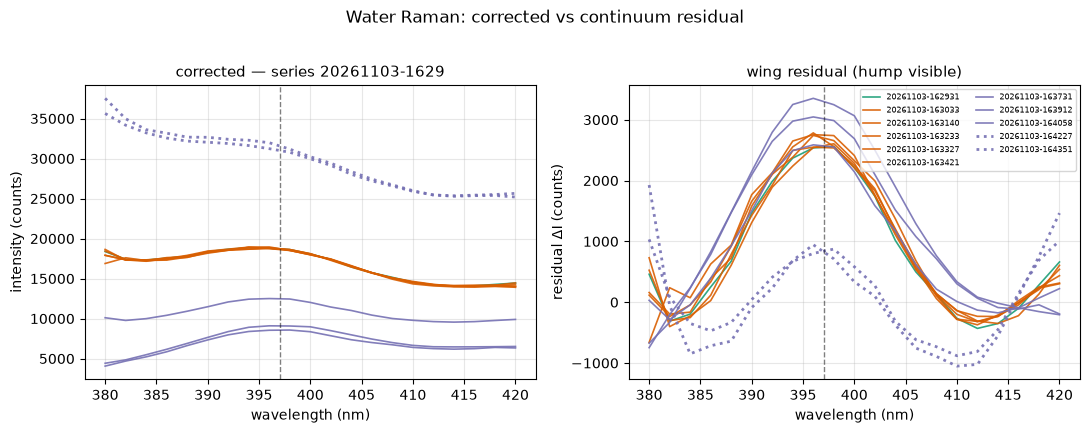

,stamp,kind,weak,sidecar_peak_nm,residual_peak_nm,residual_dI,abs_snr,contrast_snr
0,20261103-162931,sanity,False,394.0,398.0,2560.04,104.32,6.61
1,20261103-163033,technical,False,396.0,396.0,2784.26,118.34,11.46
2,20261103-163140,technical,False,394.0,396.0,2755.09,84.33,8.31
3,20261103-163233,technical,False,394.0,396.0,2549.55,90.88,11.96
4,20261103-163327,technical,False,396.0,398.0,2604.99,148.60,8.27
5,20261103-163421,technical,False,396.0,396.0,2742.57,143.27,9.77
6,20261103-163731,reseat,False,398.0,396.0,3046.59,104.29,19.01
7,20261103-163912,reseat,False,396.0,396.0,2587.67,107.19,19.15
8,20261103-164058,reseat,False,396.0,396.0,3352.41,139.25,18.61
9,20261103-164227,reseat,True,390.0,398.0,873.43,141.43,1.21


In [6]:
def attach_water_residual(run: dict) -> dict:
    sp = run["spectrum"]
    wl = sp["wavelength_nm"].to_numpy(dtype=float)
    y = sp["corrected"].to_numpy(dtype=float)
    wing = compute_wing_continuum_residual(
        wl,
        y,
        left_wing=(380.0, 386.0),
        right_wing=(410.0, 420.0),
        peak_search=(WATER_GUIDE_NM, 8.0),
    )
    contrast = None
    if wing.residual_peak_delta_i is not None:
        contrast = compute_contrast_snr(
            wing.residual,
            wing.wavelength_nm,
            residual_peak_delta_i=wing.residual_peak_delta_i,
            noise_lo_nm=410.0,
            noise_hi_nm=420.0,
            guide_nm=WATER_GUIDE_NM,
            half_window_nm=8.0,
        )
    run = dict(run)
    run["wing"] = wing
    run["residual"] = np.asarray(wing.residual, dtype=float)
    run["continuum_fit"] = np.asarray(wing.continuum_fit, dtype=float)
    run["residual_peak_nm"] = wing.residual_peak_nm
    run["residual_peak_delta_i"] = wing.residual_peak_delta_i
    run["contrast_snr"] = contrast
    run["is_weak_reseat"] = any(tag in run["stamp"] for tag in WEAK_WATER_RESEATS)
    return run


water_analyzed = [attach_water_residual(r) for r in water_runs]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for r in water_analyzed:
    kind = r["replicate_kind"]
    style = {"lw": 1.2, "alpha": 0.9}
    if r["is_weak_reseat"]:
        style.update(lw=2.0, ls=":")
    axes[0].plot(
        r["spectrum"]["wavelength_nm"],
        r["spectrum"]["corrected"],
        color=KIND_COLORS.get(kind, "#333"),
        label=r["stamp"],
        **style,
    )
    axes[1].plot(
        r["wing"].wavelength_nm,
        r["residual"],
        color=KIND_COLORS.get(kind, "#333"),
        label=r["stamp"],
        **style,
    )
axes[0].axvline(WATER_GUIDE_NM, color="k", ls="--", lw=1, alpha=0.5)
axes[1].axvline(WATER_GUIDE_NM, color="k", ls="--", lw=1, alpha=0.5)
axes[0].set_title(f"corrected — series {WATER_SERIES}")
axes[1].set_title("wing residual (hump visible)")
for ax in axes:
    ax.set_xlabel("wavelength (nm)")
axes[0].set_ylabel("intensity (counts)")
axes[1].set_ylabel("residual ΔI (counts)")
axes[1].legend(fontsize=6, ncol=2)
fig.suptitle("Water Raman: corrected vs continuum residual", y=1.02)
fig.tight_layout()
plt.show()

water_metrics = pd.DataFrame(
    [
        {
            "stamp": r["stamp"],
            "kind": r["replicate_kind"],
            "weak": r["is_weak_reseat"],
            "sidecar_peak_nm": r["peak_nm"],
            "residual_peak_nm": r["residual_peak_nm"],
            "residual_dI": r["residual_peak_delta_i"],
            "abs_snr": r["abs_snr"],
            "contrast_snr": r["contrast_snr"],
        }
        for r in water_analyzed
    ]
)
display(water_metrics.round(2))


## 5. Peak characterization (Gaussian) & spectroscopic coordinates

Gaussian on water **residual** and tonic **corrected** band near the guide.  
FWHM = `2 * sqrt(2 ln 2) * sigma`. Instrument bandpass (water 10 nm, tonic 5 nm) is annotated — broad O–H / quinine bands are **physically broad**; FWHM ≫ slit does not imply bad monochromator resolution.

**Coordinates:**

- Raman shift (cm⁻¹): `1e7 * (1/λ_ex - 1/λ_em)` with λ in nm (guide ~3400 cm⁻¹).
- Stokes shift (nm): `λ_em - λ_ex` for quinine.


Instrument bandpass: water slit=10.0 nm; tonic slit=5.0 nm


,stamp,replicate_kind,ok,mu_nm,amp,fwhm_nm,rmse,delta_nm
0,20261103-162931,sanity,True,396.54,3341.22,15.88,59.78,-0.46
1,20261103-163033,technical,True,396.37,3767.20,17.64,55.88,-0.63
2,20261103-163140,technical,True,396.17,3388.80,15.80,76.44,-0.83
3,20261103-163233,technical,True,396.75,3984.52,18.53,57.37,-0.25
4,20261103-163327,technical,True,396.89,3814.23,17.41,42.12,-0.11
5,20261103-163421,technical,True,396.73,4237.94,19.41,75.15,-0.27
6,20261103-163731,reseat,True,396.19,3193.84,15.90,71.40,-0.81
7,20261103-163912,reseat,True,396.29,3075.84,15.47,49.80,-0.71
8,20261103-164058,reseat,True,396.64,4142.72,18.42,51.63,-0.36
9,20261103-164227,reseat,True,396.33,1835.35,13.51,73.28,-0.67


,stamp,replicate_kind,ok,mu_nm,amp,fwhm_nm,rmse,delta_nm
0,20261103-194006,sanity,True,445.43,64693.85,54.77,1532.42,-4.57
1,20261103-194304,technical,True,445.71,65684.72,55.76,1457.00,-4.29
2,20261103-194554,technical,True,446.01,66400.39,55.37,1500.63,-3.99
3,20261103-194844,technical,True,445.80,64141.68,53.97,1488.09,-4.20
4,20261103-195216,reseat,True,446.28,124074.95,79.14,2317.30,-3.72
5,20261103-195549,reseat,True,448.16,57228.01,62.02,1990.40,-1.84
6,20261103-195953,reseat,True,445.94,68620.07,58.11,1497.48,-4.06


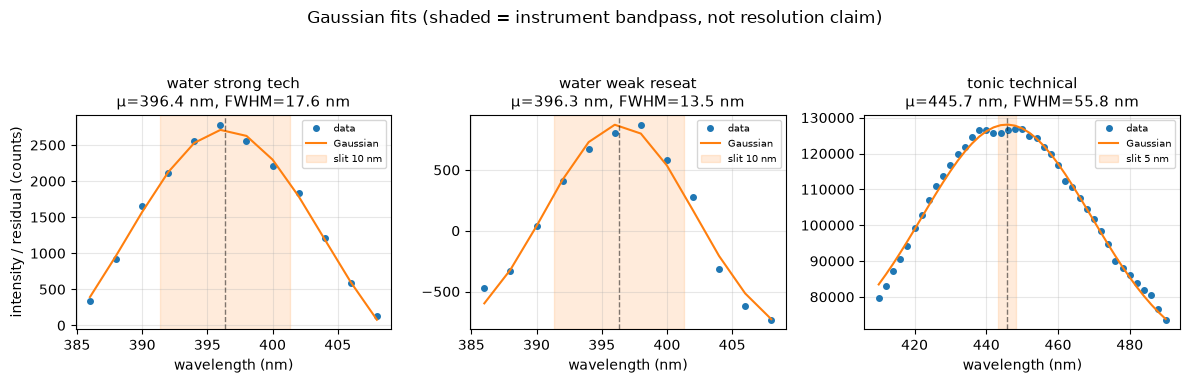

In [7]:
def gaussian(x, amp, mu, sigma, baseline):
    return amp * np.exp(-0.5 * ((x - mu) / sigma) ** 2) + baseline


def raman_shift_cm1(ex_nm: float, em_nm: float) -> float:
    return 1e7 * (1.0 / float(ex_nm) - 1.0 / float(em_nm))


def fit_gaussian(
    wl: np.ndarray,
    y: np.ndarray,
    *,
    guide_nm: float,
    half_window_nm: float,
) -> dict:
    mask = np.abs(wl - guide_nm) <= half_window_nm
    x = wl[mask]
    z = y[mask]
    if len(x) < 4:
        return {"ok": False, "reason": "too few points"}
    i0 = int(np.argmax(z))
    amp0 = float(z[i0] - np.median(z))
    mu0 = float(x[i0])
    sigma0 = max(half_window_nm / 3.0, 2.0)
    baseline0 = float(np.median(z))
    try:
        popt, _ = curve_fit(
            gaussian,
            x,
            z,
            p0=(amp0, mu0, sigma0, baseline0),
            maxfev=8000,
        )
    except Exception as exc:  # noqa: BLE001
        return {"ok": False, "reason": str(exc)}
    amp, mu, sigma, baseline = map(float, popt)
    sigma = abs(sigma)
    fwhm = 2.0 * np.sqrt(2.0 * np.log(2.0)) * sigma
    yhat = gaussian(x, *popt)
    rmse = float(np.sqrt(np.mean((z - yhat) ** 2)))
    return {
        "ok": True,
        "amp": amp,
        "mu_nm": mu,
        "sigma_nm": sigma,
        "baseline": baseline,
        "fwhm_nm": fwhm,
        "rmse": rmse,
        "x": x,
        "y": z,
        "yhat": yhat,
        "delta_nm": mu - guide_nm,
    }


def savgol_bundle(y: np.ndarray, *, window: int, poly: int = 2):
    n = len(y)
    if window % 2 == 0:
        window -= 1
    window = min(window, n if n % 2 == 1 else n - 1)
    if window < poly + 2:
        return None
    return {
        "window": window,
        "smooth": savgol_filter(y, window_length=window, polyorder=poly, deriv=0),
        "d1": savgol_filter(y, window_length=window, polyorder=poly, deriv=1),
        "d2": savgol_filter(y, window_length=window, polyorder=poly, deriv=2),
    }


def derivative_peak_nm(wl: np.ndarray, d1: np.ndarray, guide_nm: float, half_window_nm: float):
    mask = np.abs(wl - guide_nm) <= half_window_nm
    x = wl[mask]
    g = d1[mask]
    if len(x) < 2:
        return None
    for i in range(len(g) - 1):
        if g[i] >= 0 >= g[i + 1] and g[i] != g[i + 1]:
            t = g[i] / (g[i] - g[i + 1])
            return float(x[i] + t * (x[i + 1] - x[i]))
    return float(x[np.argmin(np.abs(g))])


water_fits = []
for r in water_analyzed:
    fit = fit_gaussian(
        np.asarray(r["wing"].wavelength_nm, dtype=float),
        r["residual"],
        guide_nm=WATER_GUIDE_NM,
        half_window_nm=12.0,
    )
    water_fits.append(
        {
            "stamp": r["stamp"],
            "replicate_kind": r["replicate_kind"],
            **{k: fit.get(k) for k in ("ok", "mu_nm", "amp", "fwhm_nm", "rmse", "delta_nm")},
            "_fit": fit,
        }
    )

tonic_fits = []
for r in tonic_gate:
    sp = r["spectrum"]
    fit = fit_gaussian(
        sp["wavelength_nm"].to_numpy(dtype=float),
        sp["corrected"].to_numpy(dtype=float),
        guide_nm=TONIC_GUIDE_NM,
        half_window_nm=40.0,
    )
    tonic_fits.append(
        {
            "stamp": r["stamp"],
            "replicate_kind": r["replicate_kind"],
            **{k: fit.get(k) for k in ("ok", "mu_nm", "amp", "fwhm_nm", "rmse", "delta_nm")},
            "_fit": fit,
        }
    )

print(f"Instrument bandpass: water slit={w0['slit_nm']} nm; tonic slit={t0['slit_nm']} nm")
display(pd.DataFrame([{k: v for k, v in row.items() if k != "_fit"} for row in water_fits]).round(2))
display(pd.DataFrame([{k: v for k, v in row.items() if k != "_fit"} for row in tonic_fits]).round(2))

# Example fits with bandpass annotation
strong = next(r for r in water_fits if r["replicate_kind"] == "technical" and r["ok"])
weak = next(
    (r for r in water_fits if any(t in r["stamp"] for t in WEAK_WATER_RESEATS) and r["ok"]),
    None,
)
tonic_ex_fit = next(r for r in tonic_fits if r["replicate_kind"] == "technical" and r["ok"])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, title, row, slit in (
    (axes[0], "water strong tech", strong, float(w0["slit_nm"])),
    (axes[1], "water weak reseat", weak, float(w0["slit_nm"])),
    (axes[2], "tonic technical", tonic_ex_fit, float(t0["slit_nm"])),
):
    if row is None:
        ax.set_title(f"{title}: missing")
        continue
    fit = row["_fit"]
    ax.plot(fit["x"], fit["y"], "o", ms=4, label="data")
    ax.plot(fit["x"], fit["yhat"], "-", label="Gaussian")
    ax.axvline(fit["mu_nm"], color="k", ls="--", lw=1, alpha=0.5)
    ax.axvspan(fit["mu_nm"] - slit / 2, fit["mu_nm"] + slit / 2, color="C1", alpha=0.15, label=f"slit {slit:g} nm")
    ax.set_title(f"{title}\nμ={fit['mu_nm']:.1f} nm, FWHM={fit['fwhm_nm']:.1f} nm")
    ax.set_xlabel("wavelength (nm)")
    ax.legend(fontsize=7)
axes[0].set_ylabel("intensity / residual (counts)")
fig.suptitle("Gaussian fits (shaded = instrument bandpass, not resolution claim)", y=1.05)
fig.tight_layout()
plt.show()


### 5b. Peak consensus & Raman / Stokes coordinates

Per-run: sidecar local-max, residual local-max (water), SG 1st-derivative zero, Gaussian μ. Flag disagreement when max−min of methods > slit/2.


,experiment,stamp,kind,sidecar_nm,residual_nm,sg_d1_nm,gauss_mu_nm,spread_nm,disagree,raman_cm1,raman_delta_vs_3400,stokes_nm
0,water-raman,20261103-162931,sanity,394.0,398.0,396.50,396.54,4.00,False,3353.32,-46.68,NaN
1,water-raman,20261103-163033,technical,396.0,396.0,396.27,396.37,0.37,False,3342.68,-57.32,NaN
2,water-raman,20261103-163140,technical,394.0,396.0,396.22,396.17,2.22,False,3329.59,-70.41,NaN
3,water-raman,20261103-163233,technical,394.0,396.0,396.69,396.75,2.75,False,3366.70,-33.30,NaN
4,water-raman,20261103-163327,technical,396.0,398.0,396.84,396.89,2.00,False,3375.63,-24.37,NaN
5,water-raman,20261103-163421,technical,396.0,396.0,396.73,396.73,0.73,False,3365.25,-34.75,NaN
6,water-raman,20261103-163731,reseat,398.0,396.0,396.04,396.19,2.00,False,3331.24,-68.76,NaN
7,water-raman,20261103-163912,reseat,396.0,396.0,396.13,396.29,0.29,False,3337.11,-62.89,NaN
8,water-raman,20261103-164058,reseat,396.0,396.0,396.53,396.64,0.64,False,3359.89,-40.11,NaN
9,water-raman,20261103-164227,reseat,390.0,398.0,396.56,396.33,8.00,True,3340.19,-59.81,NaN


Disagreement flags (spread > slit/2): 6 / 18


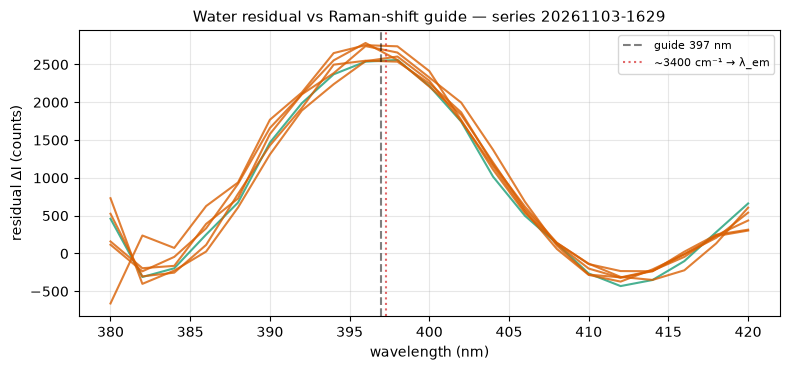

In [8]:
# Attach SG peaks + builds consensus
consensus_rows = []

for r, fitrow in zip(water_analyzed, water_fits):
    wl = np.asarray(r["wing"].wavelength_nm, dtype=float)
    bundle = savgol_bundle(r["residual"], window=7, poly=2)
    dpeak = derivative_peak_nm(wl, bundle["d1"], WATER_GUIDE_NM, 12.0) if bundle else None
    gauss_mu = fitrow.get("mu_nm") if fitrow.get("ok") else None
    methods = {
        "sidecar_nm": r["peak_nm"],
        "residual_nm": r["residual_peak_nm"],
        "sg_d1_nm": dpeak,
        "gauss_mu_nm": gauss_mu,
    }
    vals = [float(v) for v in methods.values() if v is not None]
    spread = max(vals) - min(vals) if vals else np.nan
    peak_for_shift = gauss_mu or r["residual_peak_nm"] or r["peak_nm"]
    shift = raman_shift_cm1(r["ex_nm"], peak_for_shift) if peak_for_shift else None
    consensus_rows.append(
        {
            "experiment": "water-raman",
            "stamp": r["stamp"],
            "kind": r["replicate_kind"],
            **methods,
            "spread_nm": spread,
            "disagree": spread > (float(r["slit_nm"]) / 2.0) if vals else True,
            "raman_cm1": shift,
            "raman_delta_vs_3400": (shift - WATER_RAMAN_GUIDE_CM1) if shift else None,
            "stokes_nm": None,
        }
    )
    r["sg_d1_nm"] = dpeak
    r["gauss_mu_nm"] = gauss_mu
    r["raman_cm1"] = shift

for r, fitrow in zip(tonic_gate, tonic_fits):
    wl = r["spectrum"]["wavelength_nm"].to_numpy(dtype=float)
    y = r["spectrum"]["corrected"].to_numpy(dtype=float)
    bundle = savgol_bundle(y, window=11, poly=3)
    dpeak = derivative_peak_nm(wl, bundle["d1"], TONIC_GUIDE_NM, 40.0) if bundle else None
    gauss_mu = fitrow.get("mu_nm") if fitrow.get("ok") else None
    methods = {
        "sidecar_nm": r["peak_nm"],
        "residual_nm": None,
        "sg_d1_nm": dpeak,
        "gauss_mu_nm": gauss_mu,
    }
    vals = [float(v) for v in methods.values() if v is not None]
    spread = max(vals) - min(vals) if vals else np.nan
    peak_em = gauss_mu or r["peak_nm"]
    stokes = float(peak_em) - float(r["ex_nm"]) if peak_em is not None else None
    consensus_rows.append(
        {
            "experiment": "tonic-water",
            "stamp": r["stamp"],
            "kind": r["replicate_kind"],
            **methods,
            "spread_nm": spread,
            "disagree": spread > (float(r["slit_nm"]) / 2.0) if vals else True,
            "raman_cm1": None,
            "raman_delta_vs_3400": None,
            "stokes_nm": stokes,
        }
    )
    r["sg_d1_nm"] = dpeak
    r["gauss_mu_nm"] = gauss_mu
    r["stokes_nm"] = stokes

consensus_df = pd.DataFrame(consensus_rows)
display(consensus_df.round(2))
print("Disagreement flags (spread > slit/2):", int(consensus_df["disagree"].sum()), "/", len(consensus_df))

# Raman shift overlay for water residuals (secondary x conceptually via annotation)
fig, ax = plt.subplots(figsize=(8, 3.8))
for r in water_analyzed:
    if r["replicate_kind"] not in {"technical", "sanity"}:
        continue
    ax.plot(r["wing"].wavelength_nm, r["residual"], color=KIND_COLORS[r["replicate_kind"]], alpha=0.8)
ax.axvline(WATER_GUIDE_NM, color="k", ls="--", alpha=0.5, label=f"guide {WATER_GUIDE_NM:g} nm")
ax.axvline(
    1.0 / (1.0 / 350.0 - WATER_RAMAN_GUIDE_CM1 / 1e7),
    color="C3",
    ls=":",
    alpha=0.7,
    label="~3400 cm⁻¹ → λ_em",
)
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel("residual ΔI (counts)")
ax.set_title(f"Water residual vs Raman-shift guide — series {WATER_SERIES}")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


## 6. Signal processing — Savitzky–Golay smooth & derivatives

Zero-crossing of the 1st derivative near the guide sharpens peak location vs raw local max (already folded into consensus above).


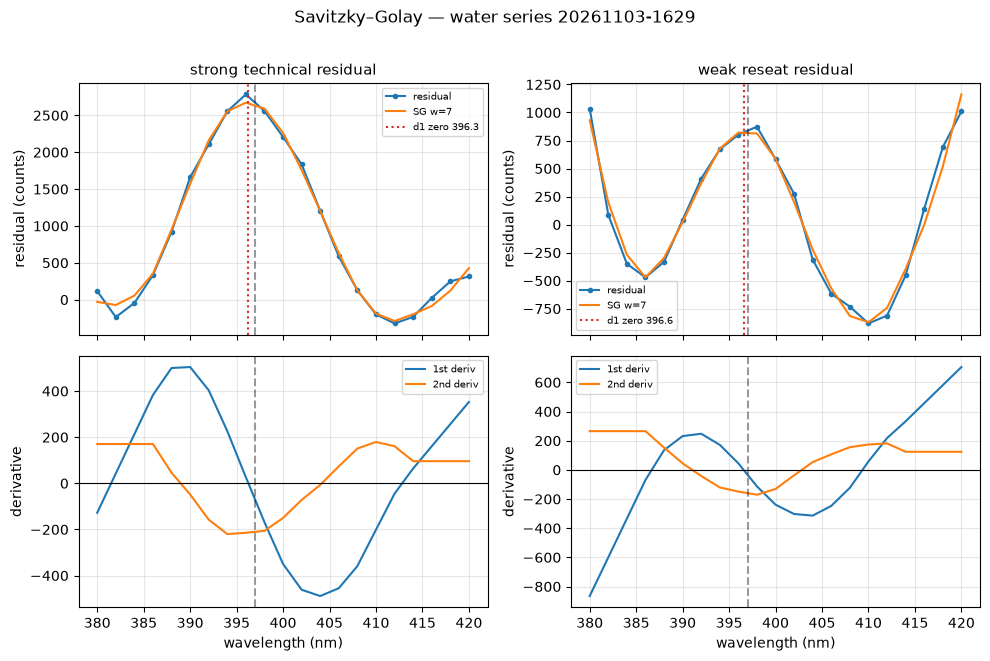

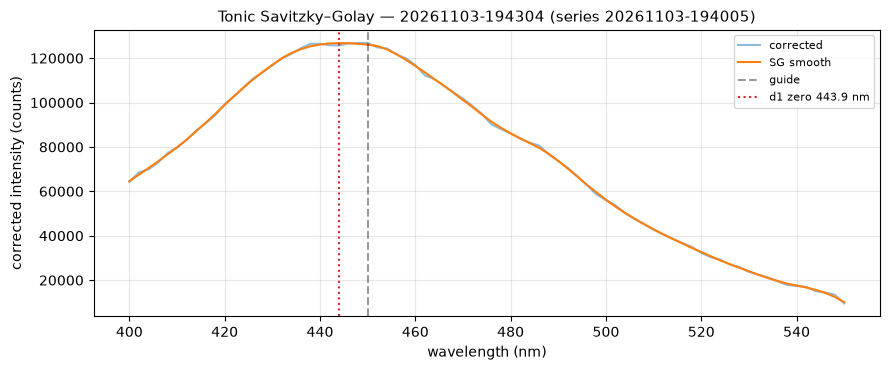

In [9]:
strong_run = next(r for r in water_analyzed if r["stamp"] == strong["stamp"])
weak_run = next((r for r in water_analyzed if weak and r["stamp"] == weak["stamp"]), None)

fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True)
for col, run, title in (
    (0, strong_run, "strong technical residual"),
    (1, weak_run, "weak reseat residual"),
):
    if run is None:
        axes[0, col].set_title(f"{title}: missing")
        continue
    wl = np.asarray(run["wing"].wavelength_nm, dtype=float)
    y = run["residual"]
    bundle = savgol_bundle(y, window=7, poly=2)
    assert bundle is not None
    dpeak = run.get("sg_d1_nm")
    axes[0, col].plot(wl, y, "o-", ms=3, label="residual")
    axes[0, col].plot(wl, bundle["smooth"], "-", label=f"SG w={bundle['window']}")
    axes[0, col].axvline(WATER_GUIDE_NM, color="k", ls="--", alpha=0.4)
    if dpeak is not None:
        axes[0, col].axvline(dpeak, color="C3", ls=":", label=f"d1 zero {dpeak:.1f}")
    axes[0, col].set_title(title)
    axes[0, col].legend(fontsize=7)
    axes[0, col].set_ylabel("residual (counts)")
    axes[1, col].plot(wl, bundle["d1"], label="1st deriv")
    axes[1, col].plot(wl, bundle["d2"], label="2nd deriv")
    axes[1, col].axhline(0, color="k", lw=0.8)
    axes[1, col].axvline(WATER_GUIDE_NM, color="k", ls="--", alpha=0.4)
    axes[1, col].legend(fontsize=7)
    axes[1, col].set_xlabel("wavelength (nm)")
    axes[1, col].set_ylabel("derivative")
fig.suptitle(f"Savitzky–Golay — water series {WATER_SERIES}", y=1.01)
fig.tight_layout()
plt.show()

t_run = next(r for r in tonic_gate if r["replicate_kind"] == "technical")
wl_t = t_run["spectrum"]["wavelength_nm"].to_numpy(dtype=float)
y_t = t_run["spectrum"]["corrected"].to_numpy(dtype=float)
bundle_t = savgol_bundle(y_t, window=11, poly=3)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(wl_t, y_t, alpha=0.5, label="corrected")
ax.plot(wl_t, bundle_t["smooth"], label="SG smooth")
ax.axvline(TONIC_GUIDE_NM, color="k", ls="--", alpha=0.4, label="guide")
if t_run.get("sg_d1_nm") is not None:
    ax.axvline(t_run["sg_d1_nm"], color="C3", ls=":", label=f"d1 zero {t_run['sg_d1_nm']:.1f} nm")
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel("corrected intensity (counts)")
ax.set_title(f"Tonic Savitzky–Golay — {t_run['stamp']} (series {TONIC_GATE_SERIES})")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


## 7. Cross-run stats — seating variance

Technical vs reseat scatter, residual/corrected correlation, PCA via SVD (demeaned). Weak water reseats marked with ×.


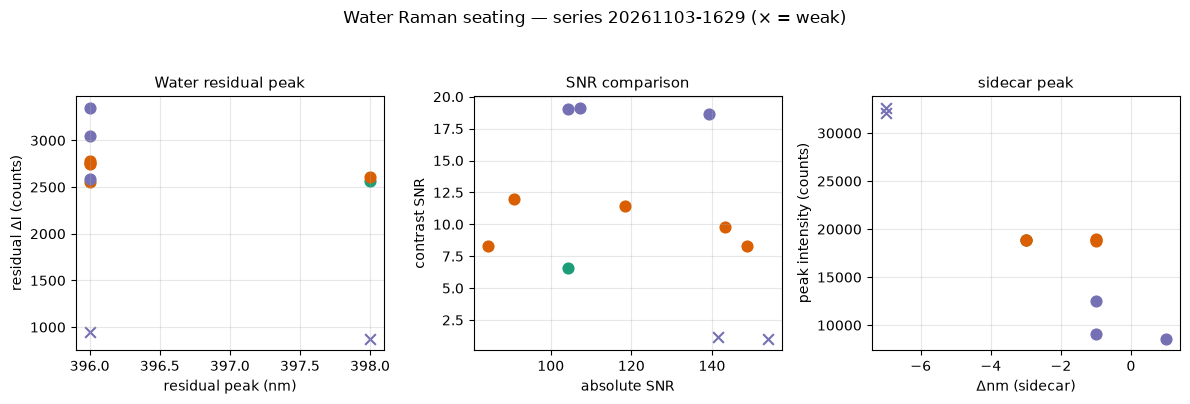

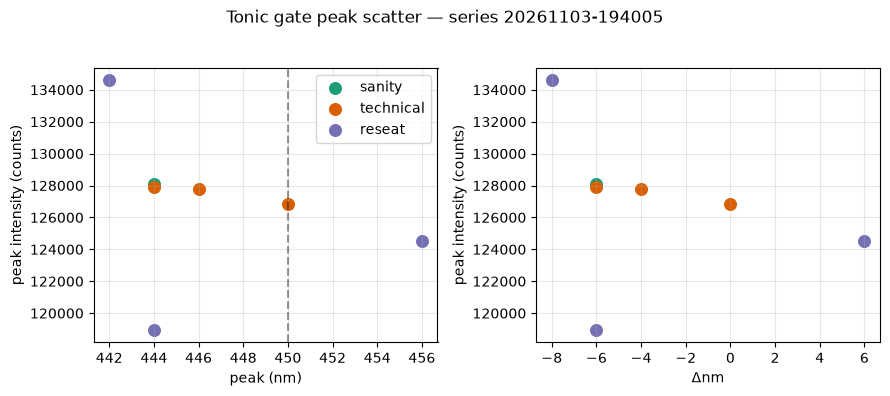

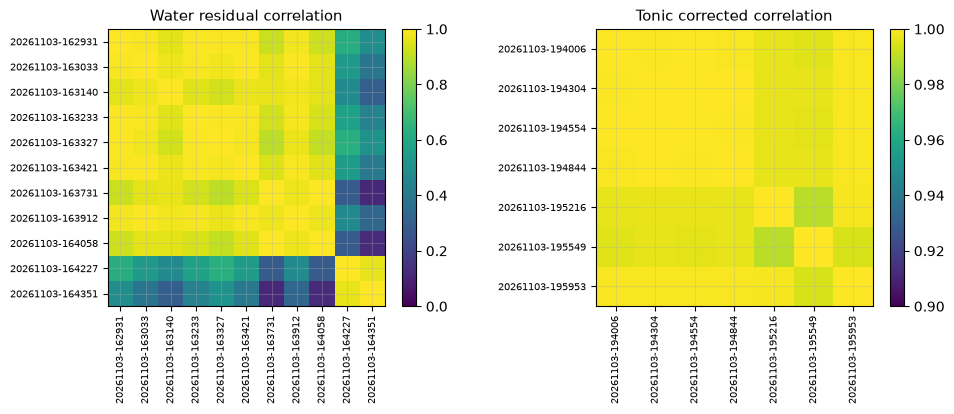

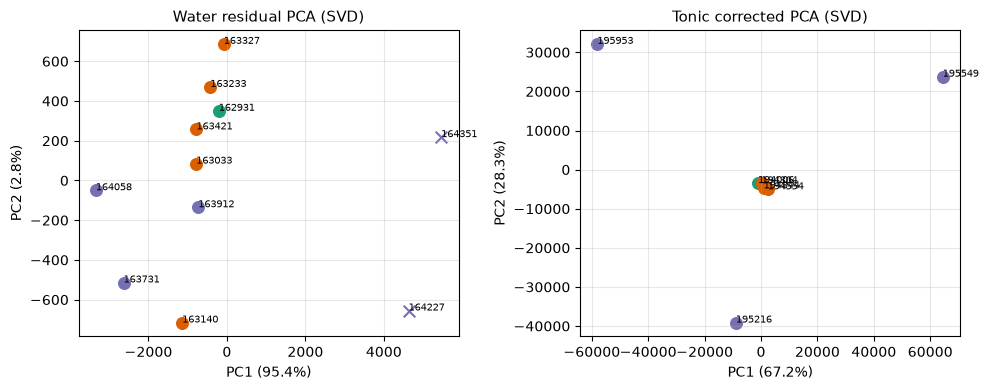

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for r in water_analyzed:
    c = KIND_COLORS.get(r["replicate_kind"], "#333")
    m = "x" if r["is_weak_reseat"] else "o"
    axes[0].scatter(r["residual_peak_nm"], r["residual_peak_delta_i"], c=c, marker=m, s=60)
    axes[1].scatter(r["abs_snr"], r["contrast_snr"], c=c, marker=m, s=60)
    axes[2].scatter(r["delta_nm"], r["peak_intensity"], c=c, marker=m, s=60)
axes[0].set_xlabel("residual peak (nm)")
axes[0].set_ylabel("residual ΔI (counts)")
axes[0].set_title("Water residual peak")
axes[1].set_xlabel("absolute SNR")
axes[1].set_ylabel("contrast SNR")
axes[1].set_title("SNR comparison")
axes[2].set_xlabel("Δnm (sidecar)")
axes[2].set_ylabel("peak intensity (counts)")
axes[2].set_title("sidecar peak")
fig.suptitle(f"Water Raman seating — series {WATER_SERIES} (× = weak)", y=1.05)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
seen = set()
for r in tonic_gate:
    c = KIND_COLORS.get(r["replicate_kind"], "#333")
    label = r["replicate_kind"] if r["replicate_kind"] not in seen else None
    seen.add(r["replicate_kind"])
    axes[0].scatter(r["peak_nm"], r["peak_intensity"], c=c, s=70, label=label)
    axes[1].scatter(r["delta_nm"], r["peak_intensity"], c=c, s=70)
axes[0].axvline(TONIC_GUIDE_NM, color="k", ls="--", alpha=0.4)
axes[0].set_xlabel("peak (nm)")
axes[0].set_ylabel("peak intensity (counts)")
axes[1].set_xlabel("Δnm")
axes[1].set_ylabel("peak intensity (counts)")
axes[0].legend()
fig.suptitle(f"Tonic gate peak scatter — series {TONIC_GATE_SERIES}", y=1.03)
fig.tight_layout()
plt.show()


def stack_vectors(runs: list[dict], key: str) -> tuple[np.ndarray, list[str]]:
    mats, labels = [], []
    for r in runs:
        v = r["residual"] if key == "residual" else r["spectrum"]["corrected"].to_numpy(dtype=float)
        mats.append(v)
        labels.append(r["stamp"])
    n = min(len(v) for v in mats)
    return np.vstack([v[:n] for v in mats]), labels


def pca_svd(X: np.ndarray, n_components: int = 2):
    Xc = X - X.mean(axis=0, keepdims=True)
    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    scores = U[:, :n_components] * S[:n_components]
    var = (S**2) / (len(X) - 1)
    explained = var / var.sum()
    return scores, explained, Vt


Xw, lab_w = stack_vectors(water_analyzed, "residual")
Xt, lab_t = stack_vectors(tonic_gate, "corrected")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
im0 = axes[0].imshow(np.corrcoef(Xw), vmin=0, vmax=1, cmap="viridis")
axes[0].set_xticks(range(len(lab_w)))
axes[0].set_yticks(range(len(lab_w)))
axes[0].set_xticklabels(lab_w, rotation=90, fontsize=7)
axes[0].set_yticklabels(lab_w, fontsize=7)
axes[0].set_title("Water residual correlation")
fig.colorbar(im0, ax=axes[0], fraction=0.046)
im1 = axes[1].imshow(np.corrcoef(Xt), vmin=0.9, vmax=1, cmap="viridis")
axes[1].set_xticks(range(len(lab_t)))
axes[1].set_yticks(range(len(lab_t)))
axes[1].set_xticklabels(lab_t, rotation=90, fontsize=7)
axes[1].set_yticklabels(lab_t, fontsize=7)
axes[1].set_title("Tonic corrected correlation")
fig.colorbar(im1, ax=axes[1], fraction=0.046)
fig.tight_layout()
plt.show()

scores_w, expl_w, _ = pca_svd(Xw)
scores_t, expl_t, _ = pca_svd(Xt)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for i, r in enumerate(water_analyzed):
    axes[0].scatter(
        scores_w[i, 0],
        scores_w[i, 1],
        c=KIND_COLORS.get(r["replicate_kind"], "#333"),
        marker=("x" if r["is_weak_reseat"] else "o"),
        s=70,
    )
    axes[0].annotate(r["stamp"][-6:], (scores_w[i, 0], scores_w[i, 1]), fontsize=7)
axes[0].set_xlabel(f"PC1 ({100 * expl_w[0]:.1f}%)")
axes[0].set_ylabel(f"PC2 ({100 * expl_w[1]:.1f}%)")
axes[0].set_title("Water residual PCA (SVD)")
for i, r in enumerate(tonic_gate):
    axes[1].scatter(
        scores_t[i, 0],
        scores_t[i, 1],
        c=KIND_COLORS.get(r["replicate_kind"], "#333"),
        s=70,
    )
    axes[1].annotate(r["stamp"][-6:], (scores_t[i, 0], scores_t[i, 1]), fontsize=7)
axes[1].set_xlabel(f"PC1 ({100 * expl_t[0]:.1f}%)")
axes[1].set_ylabel(f"PC2 ({100 * expl_t[1]:.1f}%)")
axes[1].set_title("Tonic corrected PCA (SVD)")
fig.tight_layout()
plt.show()


## 8. Metrology summary — repeatability, intermediate precision, scorecard

| Set | Meaning |
| --- | --- |
| Repeatability | `technical` only (undisturbed cuvette) |
| Intermediate precision | `reseat` only (remove/replace — seat ruggedness) |
| Combined | tech + reseat (calibration / gate set used in assessment docs) |

Sample SD with `ddof=1`. Expanded uncertainty `U = k * s / sqrt(n)` with `k=2` for technical λ only when `n >= 3` — **exploratory**, not an accredited CMC.


In [11]:
def summarize_block(df: pd.DataFrame, cols: list[str]) -> dict:
    out = {"n": int(len(df))}
    for c in cols:
        s = pd.to_numeric(df[c], errors="coerce")
        out[f"{c}_mean"] = float(s.mean()) if len(s) else np.nan
        out[f"{c}_std"] = float(s.std(ddof=1)) if len(s) > 1 else 0.0
    return out


def u_expanded(std: float, n: int, k: float = 2.0) -> float | None:
    if n < 3 or std is None or not np.isfinite(std):
        return None
    return float(k * std / np.sqrt(n))


# Enrich water metrics with gauss / raman
wf = pd.DataFrame([{k: v for k, v in row.items() if k != "_fit"} for row in water_fits])
water_m = water_metrics.merge(
    wf.rename(columns={"replicate_kind": "kind"})[["stamp", "kind", "mu_nm", "fwhm_nm", "delta_nm"]],
    on=["stamp", "kind"],
    how="left",
    suffixes=("", "_fit"),
)
water_m = water_m.merge(
    consensus_df.loc[consensus_df["experiment"] == "water-raman", ["stamp", "raman_cm1", "sg_d1_nm"]],
    on="stamp",
    how="left",
)
water_m["delta_residual_nm"] = water_m["residual_peak_nm"] - WATER_GUIDE_NM

tonic_m = meta_df[
    (meta_df["experiment"] == "tonic-water") & (meta_df["series_id"] == TONIC_GATE_SERIES)
].copy()
tf = pd.DataFrame([{k: v for k, v in row.items() if k != "_fit"} for row in tonic_fits])
tonic_m = tonic_m.merge(
    tf[["stamp", "replicate_kind", "mu_nm", "fwhm_nm"]],
    left_on=["stamp", "replicate_kind"],
    right_on=["stamp", "replicate_kind"],
    how="left",
)
tonic_m = tonic_m.merge(
    consensus_df.loc[consensus_df["experiment"] == "tonic-water", ["stamp", "stokes_nm", "sg_d1_nm"]],
    on="stamp",
    how="left",
)

water_cols = [
    "residual_peak_nm",
    "delta_residual_nm",
    "residual_dI",
    "abs_snr",
    "contrast_snr",
    "mu_nm",
    "fwhm_nm",
    "raman_cm1",
]
tonic_cols = ["peak_nm", "delta_nm", "peak_intensity", "mu_nm", "fwhm_nm", "stokes_nm"]

metrology_rows = []
for label, kind_filter in (
    ("repeatability (technical)", ["technical"]),
    ("intermediate precision (reseat)", ["reseat"]),
    ("combined tech+reseat", ["technical", "reseat"]),
):
    wsub = water_m[water_m["kind"].isin(kind_filter)]
    tsub = tonic_m[tonic_m["replicate_kind"].isin(kind_filter)]
    wblock = summarize_block(wsub, water_cols)
    tblock = summarize_block(tsub, tonic_cols)
    metrology_rows.append(
        {
            "set": label,
            "experiment": "water-raman",
            **wblock,
            "U95_residual_peak_nm": u_expanded(wblock.get("residual_peak_nm_std"), wblock["n"]),
        }
    )
    metrology_rows.append(
        {
            "set": label,
            "experiment": "tonic-water",
            **tblock,
            "U95_peak_nm": u_expanded(tblock.get("peak_nm_std"), tblock["n"])
            if kind_filter == ["technical"]
            else None,
        }
    )

metrology_df = pd.DataFrame(metrology_rows)
# Present compact views
water_metro = metrology_df[metrology_df["experiment"] == "water-raman"][
    [
        "set",
        "n",
        "residual_peak_nm_mean",
        "residual_peak_nm_std",
        "delta_residual_nm_mean",
        "delta_residual_nm_std",
        "residual_dI_mean",
        "residual_dI_std",
        "abs_snr_mean",
        "contrast_snr_mean",
        "raman_cm1_mean",
        "fwhm_nm_mean",
        "U95_residual_peak_nm",
    ]
]
tonic_metro = metrology_df[metrology_df["experiment"] == "tonic-water"][
    [
        "set",
        "n",
        "peak_nm_mean",
        "peak_nm_std",
        "delta_nm_mean",
        "delta_nm_std",
        "peak_intensity_mean",
        "peak_intensity_std",
        "stokes_nm_mean",
        "fwhm_nm_mean",
        "U95_peak_nm",
    ]
]
display(water_metro.round(2))
display(tonic_metro.round(2))

# Brochure scorecard (DIY fixture language matches measured-vs-specs)
w_tech = water_m[water_m["kind"] == "technical"]
t_tech = tonic_m[tonic_m["replicate_kind"] == "technical"]
w_comb = water_m[water_m["kind"].isin(["technical", "reseat"])]
t_comb = tonic_m[tonic_m["replicate_kind"].isin(["technical", "reseat"])]

scorecard = pd.DataFrame(
    [
        {
            "domain": "Wavelength accuracy (±1.0 nm brochure)",
            "water": f"tech residual Δ ≈ {w_tech['delta_residual_nm'].mean():+.1f} nm",
            "tonic": f"gate Δ ≈ {t_comb['delta_nm'].mean():+.1f} ± {t_comb['delta_nm'].std(ddof=1):.1f} nm",
            "status": "DIY OK / factory open",
        },
        {
            "domain": "Wavelength reproducibility (±0.5 nm)",
            "water": f"tech σ ≈ {w_tech['residual_peak_nm'].std(ddof=1):.1f} nm; reseat worse",
            "tonic": f"tech σ ≈ {t_tech['peak_nm'].std(ddof=1):.1f} nm; reseat worse",
            "status": "Not met (seating-limited)",
        },
        {
            "domain": "Water Raman sensitivity (500:1 RMS)",
            "water": f"abs SNR ~{w_comb['abs_snr'].mean():.0f}; contrast SNR ~{w_comb['contrast_snr'].mean():.1f}",
            "tonic": "n/a",
            "status": "Not met (fixture) — not a factory claim",
        },
        {
            "domain": "Fluorescence usefulness (quinine ~450 nm)",
            "water": "n/a",
            "tonic": f"peak {t_comb['peak_nm'].mean():.1f}±{t_comb['peak_nm'].std(ddof=1):.1f} nm; I~{t_comb['peak_intensity'].mean()/1e3:.1f}k",
            "status": "Go (unclipped at ~1:450)",
        },
        {
            "domain": "Dynamic range / clip",
            "water": "no overload in series",
            "tonic": "clips at 1:1 / 1:2 / ~1:90; clear at ~1:450",
            "status": "Behaves as designed",
        },
    ]
)
display(scorecard)

print(
    "Baseline cross-check (docs/assessment):\n"
    "  water: residual hump ~396-398 nm on good seats; abs SNR ~123 combined\n"
    "  tonic: peak 447.0+/-5.2 nm, intensity ~126.8k+/-5.1k"
)


,set,n,residual_peak_nm_mean,residual_peak_nm_std,delta_residual_nm_mean,delta_residual_nm_std,residual_dI_mean,residual_dI_std,abs_snr_mean,contrast_snr_mean,raman_cm1_mean,fwhm_nm_mean,U95_residual_peak_nm
0,repeatability (technical),5,396.4,0.89,-0.6,0.89,2687.29,103.44,117.08,9.95,3355.97,17.76,0.80
2,intermediate precision (reseat),5,396.4,0.89,-0.6,0.89,2161.04,1174.94,129.21,11.80,3342.01,15.06,0.80
4,combined tech+reseat,10,396.4,0.84,-0.6,0.84,2424.17,833.81,123.15,10.88,3348.99,16.41,0.53


,set,n,peak_nm_mean,peak_nm_std,delta_nm_mean,delta_nm_std,peak_intensity_mean,peak_intensity_std,stokes_nm_mean,fwhm_nm_mean,U95_peak_nm
1,repeatability (technical),3,446.67,3.06,-3.33,3.06,127526.67,591.10,95.84,55.03,3.53
3,intermediate precision (reseat),3,447.33,7.57,-2.67,7.57,126005.67,7928.62,96.79,66.43,NaN
5,combined tech+reseat,6,447.00,5.18,-3.00,5.18,126766.17,5096.96,96.32,60.73,NaN


,domain,water,tonic,status
0,Wavelength accuracy (±1.0 nm brochure),tech residual Δ ≈ -0.6 nm,gate Δ ≈ -3.0 ± 5.2 nm,DIY OK / factory open
1,Wavelength reproducibility (±0.5 nm),tech σ ≈ 0.9 nm; reseat worse,tech σ ≈ 3.1 nm; reseat worse,Not met (seating-limited)
2,Water Raman sensitivity (500:1 RMS),abs SNR ~123; contrast SNR ~10.9,n/a,Not met (fixture) — not a factory claim
3,Fluorescence usefulness (quinine ~450 nm),n/a,peak 447.0±5.2 nm; I~126.8k,Go (unclipped at ~1:450)
4,Dynamic range / clip,no overload in series,clips at 1:1 / 1:2 / ~1:90; clear at ~1:450,Behaves as designed


Baseline cross-check (docs/assessment):
  water: residual hump ~396-398 nm on good seats; abs SNR ~123 combined
  tonic: peak 447.0+/-5.2 nm, intensity ~126.8k+/-5.1k


## Appendix — spatial-frequency QC (FFT / Welch)

Wavelength is the independent axis (Δλ = 2 nm → Nyquist 0.25 cycles/nm). This section is a **noise / clip fingerprint only** — not a sensitivity claim. Prefer residual ΔI and contrast SNR for primary conclusions.

- Water residual: N≈21 → coarse bins; HF power can still separate weak reseats qualitatively.
- Tonic Welch PSD: clipped flat-tops inject broadband energy vs unclipped gate.
- Interpolation to 0.5 nm is visualization-only and **does not** add optical resolution.


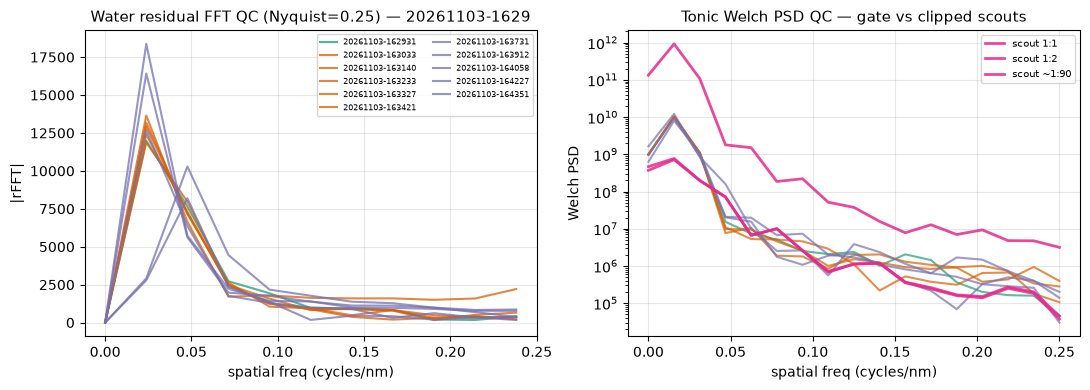

,stamp,kind,weak,hf_power,n
0,20261103-162931,sanity,False,108004.0342,21
1,20261103-163033,technical,False,67418.4859,21
2,20261103-163140,technical,False,393968.8937,21
3,20261103-163233,technical,False,49576.5953,21
4,20261103-163327,technical,False,91946.9180,21
5,20261103-163421,technical,False,78759.8744,21
6,20261103-163731,reseat,False,190216.6770,21
7,20261103-163912,reseat,False,78621.3994,21
8,20261103-164058,reseat,False,157223.3887,21
9,20261103-164227,reseat,True,36042.4773,21


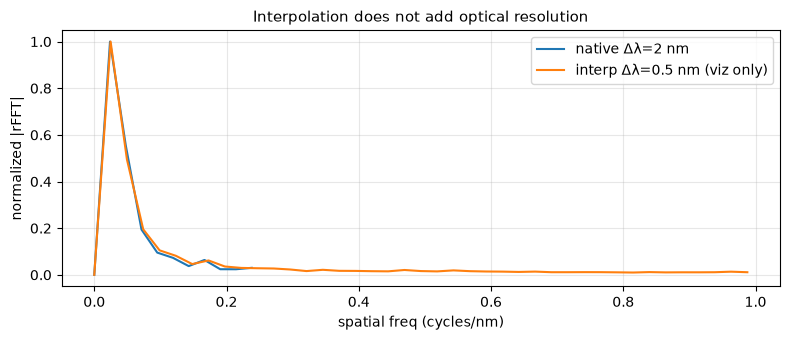

In [12]:
def spatial_fft(y: np.ndarray, d_lambda_nm: float = 2.0):
    y = np.asarray(y, dtype=float)
    y = y - np.mean(y)
    x = np.arange(len(y), dtype=float)
    coef = np.polyfit(x, y, 1)
    y = y - np.polyval(coef, x)
    spec = np.fft.rfft(y)
    freqs = np.fft.rfftfreq(len(y), d=d_lambda_nm)
    return freqs, np.abs(spec), y


def hf_power(freqs: np.ndarray, mag: np.ndarray, f_cut: float = 0.08) -> float:
    mask = freqs >= f_cut
    if not np.any(mask):
        return float("nan")
    return float(np.trapezoid(mag[mask] ** 2, freqs[mask]))


fig, axes = plt.subplots(1, 2, figsize=(11, 4))
rows = []
for r in water_analyzed:
    freqs, mag, _ = spatial_fft(r["residual"])
    axes[0].plot(
        freqs,
        mag,
        color=KIND_COLORS.get(r["replicate_kind"], "#333"),
        alpha=0.75,
        label=r["stamp"],
    )
    rows.append(
        {
            "stamp": r["stamp"],
            "kind": r["replicate_kind"],
            "weak": r["is_weak_reseat"],
            "hf_power": hf_power(freqs, mag),
            "n": len(r["residual"]),
        }
    )
axes[0].set_xlabel("spatial freq (cycles/nm)")
axes[0].set_ylabel("|rFFT|")
axes[0].set_title(f"Water residual FFT QC (Nyquist=0.25) — {WATER_SERIES}")
axes[0].legend(fontsize=6, ncol=2)

for r in tonic_gate:
    y = r["spectrum"]["corrected"].to_numpy(dtype=float)
    y = y - np.mean(y)
    f, pxx = welch(y, fs=1.0 / 2.0, nperseg=min(32, len(y)))
    axes[1].semilogy(f, pxx, color=KIND_COLORS.get(r["replicate_kind"], "#333"), alpha=0.7)
for r in tonic_scouts:
    y = r["spectrum"]["corrected"].to_numpy(dtype=float)
    y = y - np.mean(y)
    f, pxx = welch(y, fs=1.0 / 2.0, nperseg=min(32, len(y)))
    axes[1].semilogy(f, pxx, color="#e7298a", alpha=0.85, lw=2, label=f"scout {r['dilution']}")
axes[1].set_xlabel("spatial freq (cycles/nm)")
axes[1].set_ylabel("Welch PSD")
axes[1].set_title("Tonic Welch PSD QC — gate vs clipped scouts")
handles, labels = axes[1].get_legend_handles_labels()
axes[1].legend(dict(zip(labels, handles)).values(), dict(zip(labels, handles)).keys(), fontsize=7)
fig.tight_layout()
plt.show()

display(pd.DataFrame(rows).round(4))

# Interp caveat figure
r = strong_run
wl = np.asarray(r["wing"].wavelength_nm, dtype=float)
y = r["residual"]
wl_f = np.arange(wl.min(), wl.max() + 0.5, 0.5)
y_f = np.interp(wl_f, wl, y)
f0, m0, _ = spatial_fft(y, d_lambda_nm=2.0)
f1, m1, _ = spatial_fft(y_f, d_lambda_nm=0.5)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(f0, m0 / m0.max(), label="native Δλ=2 nm")
ax.plot(f1, m1 / m1.max(), label="interp Δλ=0.5 nm (viz only)")
ax.set_xlabel("spatial freq (cycles/nm)")
ax.set_ylabel("normalized |rFFT|")
ax.set_title("Interpolation does not add optical resolution")
ax.legend()
fig.tight_layout()
plt.show()


## Results, limitations, next action

### Results
1. **Water Raman:** continuum residual peaks near the 397 nm / ~3400 cm⁻¹ guide on good seats; contrast SNR separates weak reseats from absolute-peak SNR (which remains flattering).
2. **Tonic:** unclipped quinine band near ~447 nm (Stokes ~97 nm) at ~1:450; technical intensity tight, reseat λ scatter larger.
3. **Precision:** technical repeatability is tighter than reseat intermediate precision — seating dominates brochure `±0.5 nm` reproducibility.
4. **Dynamic range:** tonic clip ladder behaves as designed; working unclipped dilution on this mixer is ~1:450 at 5 nm slits.

### Limitations
- DIY Al block (Gate D open): **not** `L2250140`; do not claim factory `500:1`, `±1.0 nm`, or `±0.5 nm`.
- Intensities are uncorrected Em counts; no emission response curve.
- Water N≈21 limits lineshape/FFT detail; Gaussian FWHM ≫ slit reflects broad O–H / quinine bands.
- Exploratory U(k=2) is not an accredited uncertainty.

### Next Gate D action
Positive, repeatable cuvette seat and secure the block; then re-run short water-Raman + tonic technical series before quantitative FWHM / SNR / linearity claims.
